# 02 · Retrieval: which strategy finds the right passage?

The assistant can only answer well if it is shown the right passage, so retrieval is evaluated on its
own first, before any LLM is involved.

**The evaluation set** (`data/eval/questions.csv`) has 110 questions: 98 answerable from the corpus and
12 that are not. Each answerable question is labelled with the document and a short **evidence quote**
that contains the answer. A retrieved chunk counts as relevant if it contains at least half of that
quote, so the labels don't depend on how the text was chunked (see `evaluation.py`).

The questions are written in all three languages, and **58% of them are cross-language**: the question is in
one language and the answer only exists in another, e.g. a French question about gradient descent, which is only
covered in the English course. That is the normal situation for a student whose courses mix languages.

**Metrics.** `recall@k` = share of questions with a relevant chunk in the top k. The LLM gets the top 5, so
recall@5 is the one that matters most for answers. `MRR@10` = mean of 1/rank of the first relevant chunk, which
rewards putting it at the top. All numbers come from `scripts/evaluate_retrieval.py`.

In [1]:
import os
import sys
sys.path.insert(0, "../src")
os.environ.setdefault("COURSE_RAG_DEVICE", "cpu")  # the extra experiments below only embed 98 short queries

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from course_rag import plots
from course_rag.config import FIGURES_DIR, METRICS_DIR
from course_rag.evaluation import first_relevant_rank, load_questions, retrieval_metrics

plots.setup()
pd.set_option("display.max_colwidth", 100)
questions = load_questions()
answerable = [q for q in questions if q.answerable]
qdf = pd.DataFrame([{"qid": q.qid, "q_lang": q.q_lang, "doc_lang": q.doc_lang, "kind": q.kind} for q in questions])
print(qdf.kind.value_counts().to_string(), "\n")
pd.crosstab(qdf.q_lang, qdf.doc_lang.fillna("(none)"), rownames=["question in"], colnames=["answer in"])

kind
cross-language    57
same-language     41
unanswerable      12 



answer in,(none),ar,en,fr
question in,,,,
ar,4,14,10,8
en,4,9,14,11
fr,4,7,12,13


In [2]:
per_q = pd.read_csv(METRICS_DIR / "retrieval_per_question.csv")
summary = json.loads((METRICS_DIR / "retrieval.json").read_text(encoding="utf-8"))

def ranks_of(config):
    g = per_q[per_q.config == config]
    return [None if pd.isna(r) else int(r) for r in g["rank"]]

MAIN = {"bm25 | bge-m3 | 1000": "BM25", "dense | bge-m3 | 1000": "Dense (bge-m3)",
        "hybrid | bge-m3 | 1000": "Hybrid (BM25 + dense, RRF)", "dense_rerank | bge-m3 | 1000": "Dense + reranker",
        "hybrid_rerank | bge-m3 | 1000": "Hybrid + reranker"}
rows = []
for config, name in MAIN.items():
    s = summary[config]
    rows.append({"strategy": name, **{k: s["overall"][k] for k in ["recall@1", "recall@3", "recall@5", "recall@10", "mrr@10"]},
                 "recall@5 95% CI": "{:.2f}–{:.2f}".format(*s["overall"]["recall@5_ci"]),
                 "R@1 same-lang": s["by_kind"]["same-language"]["recall@1"],
                 "R@1 cross-lang": s["by_kind"]["cross-language"]["recall@1"],
                 "median ms": s["overall"]["latency_ms"]})
main = pd.DataFrame(rows).set_index("strategy")
main.round(3)

,recall@1,recall@3,recall@5,recall@10,mrr@10,recall@5 95% CI,R@1 same-lang,R@1 cross-lang,median ms
strategy,,,,,,,,,
BM25,0.327,0.500,0.541,0.612,0.423,0.45–0.64,0.707,0.053,1.10
Dense (bge-m3),0.684,0.898,0.939,0.969,0.795,0.89–0.98,0.707,0.667,18.20
"Hybrid (BM25 + dense, RRF)",0.429,0.745,0.786,0.929,0.601,0.70–0.87,0.683,0.246,19.00
Dense + reranker,0.796,0.959,0.959,0.959,0.869,0.92–0.99,0.780,0.807,136.35
Hybrid + reranker,0.806,0.969,0.969,0.969,0.881,0.93–1.00,0.780,0.825,132.75


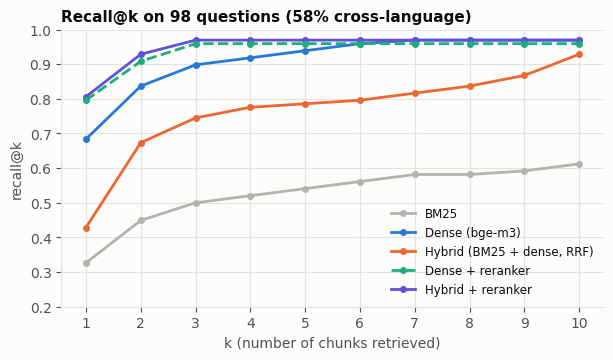

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ks = np.arange(1, 11)
colors = [plots.MUTED, plots.SERIES[0], plots.SERIES[1], plots.SERIES[2], plots.SERIES[6]]
for (config, name), color in zip(MAIN.items(), colors):
    r = ranks_of(config)
    curve = [np.mean([x is not None and x <= k for x in r]) for k in ks]
    dashed = config.startswith("dense_rerank")  # it lies almost exactly under hybrid + reranker
    ax.plot(ks, curve, color=color, linewidth=2, marker="o", markersize=4, label=name,
            linestyle="--" if dashed else "-", zorder=3 if dashed else 2)
ax.set_xticks(ks); ax.set_xlabel("k (number of chunks retrieved)"); ax.set_ylabel("recall@k")
ax.set_ylim(0.2, 1.0)
ax.set_title("Recall@k on 98 questions (58% cross-language)")
ax.legend(loc="lower right", fontsize=8.5)
fig.savefig(FIGURES_DIR / "recall_at_k.png")
plt.show()

**Two results stand out.**

1. **The cross-encoder reranker is the biggest single gain**: recall@1 goes from 0.68 to 0.81 and MRR from 0.80
   to 0.88, for about 120 ms per question.
2. **Hybrid search on its own is *worse* than dense search.** That surprised me, because BM25 + vectors with
   reciprocal rank fusion is the standard recommendation. Splitting by question type shows why:

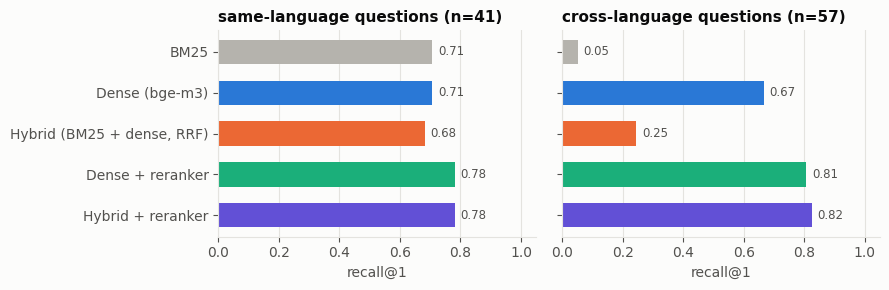

In [4]:
kinds = ["same-language", "cross-language"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), sharey=True)
names = list(MAIN.values())
y = np.arange(len(names))
for ax, kind in zip(axes, kinds):
    vals = [summary[c]["by_kind"][kind]["recall@1"] for c in MAIN]
    bars = ax.barh(y, vals, height=0.6, color=[plots.MUTED, plots.SERIES[0], plots.SERIES[1], plots.SERIES[2], plots.SERIES[6]])
    plots.label_bars(ax, bars)
    n = summary["dense | bge-m3 | 1000"]["by_kind"][kind]["n"]
    ax.set_title(f"{kind} questions (n={n})"); ax.set_xlim(0, 1.05); ax.grid(axis="y", visible=False)
    ax.set_xlabel("recall@1")
axes[0].set_yticks(y, names); axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "same_vs_cross_language.png")
plt.show()

- On **same-language** questions BM25 is as good as dense retrieval at rank 1 (0.71 each), and fusing them
  changes little.
- On **cross-language** questions BM25 is close to useless (0.05). A French question shares almost no words
  with the English passage that answers it. Reciprocal rank fusion gives BM25's list the same weight as the
  dense list anyway, so for those questions it pushes confidently wrong same-language chunks into the top
  ranks. Dense recall@1 drops from 0.67 to 0.25.
- The **reranker** reads question and passage together and isn't fooled by shared words, so it recovers
  either way: 0.78 on same-language and 0.81–0.83 on cross-language questions, whichever first stage feeds it.

Here is what that looks like for one question:

In [5]:
from course_rag.index import SearchIndex
index = SearchIndex.load(with_reranker=False)
q = next(q for q in answerable if q.qid == "q008")  # French question, answer only in the Arabic course
print(q.question, "→ answer in", q.evidence[0][0], "\n")
for mode in ["bm25", "dense", "hybrid"]:
    hits = index.retriever(mode).search(q.question, 3)
    print(f"{mode:7s}", "  ".join(f"{d.metadata['chunk_id']}{' ✓' if first_relevant_rank([d], q) else ''}" for d in hits))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

À quoi sert le champ « taille de la fenêtre » dans l'en-tête TCP ? → answer in ar/tcp 

bm25    fr/memoire-virtuelle#003  fr/memoire-virtuelle#027  fr/memoire-virtuelle#020


dense   ar/tcp#003 ✓  ar/jidar-himaya#004  ar/tcp#002
hybrid  fr/memoire-virtuelle#001  fr/memoire-virtuelle#020  ar/jidar-himaya#004


Dense retrieval puts the Arabic TCP header passage first. BM25 matches the French words (*taille*, *fenêtre*,
*en-tête*) to the French virtual-memory course, and in the fused list those chunks push the right one down
to rank 10.

### Could a lower BM25 weight fix hybrid?

RRF can weight the lists. Below is a sweep of the BM25 weight (dense stays at 1). **This is exploratory:
it is tuned on the test questions, so it can't be used to claim a result**. It only shows the shape of the
trade-off.

In [6]:
from course_rag.retrievers import HybridRetriever
rows = []
for w in [0.0, 0.1, 0.25, 0.5, 1.0]:
    retriever = HybridRetriever(retrievers=[index.bm25, index.dense], weights=[w, 1.0])
    ranks = [first_relevant_rank(retriever.search(q.question, 10), q) for q in answerable]
    for kind in kinds:
        sel = [r for r, q in zip(ranks, answerable) if q.kind == kind]
        rows.append({"BM25 weight": w, "kind": kind, **retrieval_metrics(sel)})
sweep = pd.DataFrame(rows).pivot(index="BM25 weight", columns="kind", values=["recall@1", "mrr@10"])
sweep.round(3)

recall@1                       mrr@10              
kind        cross-language same-language cross-language same-language
BM25 weight                                                          
0.00                 0.667         0.707          0.774         0.823
0.10                 0.544         0.707          0.678         0.824
0.25                 0.491         0.756          0.610         0.850
0.50                 0.421         0.732          0.558         0.841
1.00                 0.246         0.683          0.446         0.816

At low weights BM25 does help a little on same-language questions, but every step up in weight costs more
on cross-language questions than it gains. With most questions crossing languages, there is no weight at
which hybrid clearly beats dense. With the reranker the question mostly goes away (next cell): it rescores
whatever the first stage hands it, and the two candidate pools are nearly equally good. A relevant chunk is in
hybrid's top 30 for 97 of the 98 questions, and in dense's top 30 for 96.

In [7]:
def paired_bootstrap(a, b, n_boot=5000, seed=0):
    """95% CI of mean(b - a) over questions, resampling questions."""
    rng = np.random.default_rng(seed)
    d = np.asarray(b, float) - np.asarray(a, float)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    return d.mean(), np.percentile(d[idx].mean(axis=1), [2.5, 97.5])

def rr(config):
    return [0 if r is None else 1 / r for r in ranks_of(config)]

for base, other in [("dense | bge-m3 | 1000", "hybrid | bge-m3 | 1000"),
                    ("dense | bge-m3 | 1000", "dense_rerank | bge-m3 | 1000"),
                    ("dense | bge-m3 | 1000", "hybrid_rerank | bge-m3 | 1000"),
                    ("dense_rerank | bge-m3 | 1000", "hybrid_rerank | bge-m3 | 1000")]:
    mean, (lo, hi) = paired_bootstrap(rr(base), rr(other))
    print(f"MRR  {MAIN[other]:28s} vs {MAIN[base]:17s}: {mean:+.3f}  (95% CI {lo:+.3f} to {hi:+.3f})")

MRR  Hybrid (BM25 + dense, RRF)   vs Dense (bge-m3)   : -0.193  (95% CI -0.267 to -0.122)
MRR  Dense + reranker             vs Dense (bge-m3)   : +0.074  (95% CI +0.023 to +0.131)
MRR  Hybrid + reranker            vs Dense (bge-m3)   : +0.086  (95% CI +0.032 to +0.146)
MRR  Hybrid + reranker            vs Dense + reranker : +0.012  (95% CI +0.000 to +0.034)


The reranker's gain over plain dense retrieval is clearly real (the interval is well above zero). Hybrid on its
own is clearly worse. Hybrid + reranker vs dense + reranker: +0.012 MRR, with an interval that starts at zero. That's the
one extra question whose answer only hybrid's candidate pool contains. At most, a small edge.

I serve **hybrid + reranker** by default. On this set it is at least as good and costs nothing extra, and BM25 is the safety net for
a kind of query this set barely contains: exact identifiers a student copies from a slide (`sem_post`,
`RFC 793`, an error code), which embeddings handle poorly. But to be clear, the measured improvement in this
project comes from the **reranker**, not from adding BM25.

## Embedding model: does "multilingual" matter?

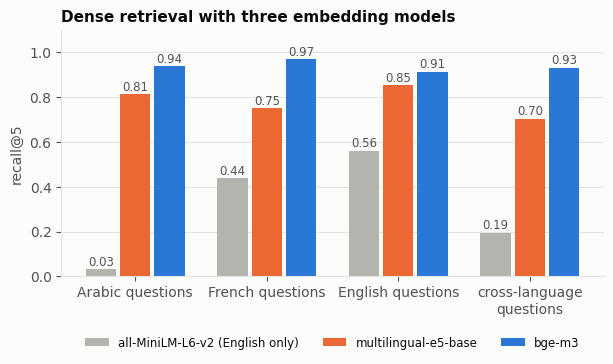

In [8]:
EMB = {"dense | all-MiniLM-L6-v2 | 1000": "all-MiniLM-L6-v2 (English only)",
       "dense | multilingual-e5-base | 1000": "multilingual-e5-base",
       "dense | bge-m3 | 1000": "bge-m3"}
cols = ["ar", "fr", "en"]
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(cols) + 1)
w = 0.26
for i, (config, name) in enumerate(EMB.items()):
    s = summary[config]
    vals = [s["by_question_language"][l]["recall@5"] for l in cols] + [s["by_kind"]["cross-language"]["recall@5"]]
    bars = ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=[plots.MUTED, plots.SERIES[1], plots.SERIES[0]][i], label=name)
    plots.label_bars(ax, bars)
ax.set_xticks(x, ["Arabic questions", "French questions", "English questions", "cross-language\nquestions"])
ax.set_ylim(0, 1.1); ax.set_ylabel("recall@5"); ax.grid(axis="x", visible=False)
ax.set_title("Dense retrieval with three embedding models")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8.5)
fig.savefig(FIGURES_DIR / "embedding_models.png")
plt.show()

- An English-only model (MiniLM) is not an option: **0.03 recall@5 on Arabic questions**. Its tokenizer
  barely knows the Arabic script.
- `multilingual-e5-base` is fine within a language but loses a lot across languages (0.70 recall@5 on cross-language
  questions vs 0.93 for bge-m3).
- `bge-m3` (568M parameters, 8k context) is the clear choice, and at 1,267 chunks it embeds the whole corpus in 6 seconds.

## Chunk size

In [9]:
rows = []
for size in [500, 1000, 1500]:
    for mode in ["dense", "hybrid_rerank"]:
        s = summary[f"{mode} | bge-m3 | {size}"]["overall"]
        rows.append({"chunk size (chars)": size, "strategy": mode, "recall@1": s["recall@1"], "recall@5": s["recall@5"],
                     "mrr@10": s["mrr@10"], "median ms": s["latency_ms"]})
pd.DataFrame(rows).set_index(["strategy", "chunk size (chars)"]).round(3)

,,recall@1,recall@5,mrr@10,median ms
strategy,chunk size (chars),,,,
dense,500,0.694,0.888,0.785,17.70
hybrid_rerank,500,0.816,0.949,0.869,84.00
dense,1000,0.684,0.939,0.795,18.20
hybrid_rerank,1000,0.806,0.969,0.881,132.75
dense,1500,0.633,0.908,0.753,17.30
hybrid_rerank,1500,0.806,0.959,0.873,180.50


With the reranker, chunk size barely matters here: differences are one or two questions out of 98. Without
it, 1,000 characters is a bit better than both neighbours at recall@5. Smaller chunks rerank faster (shorter inputs) but
give the LLM less context per source, so 1,000 stays the default.

## What the best system still misses

In [10]:
from course_rag.ingest import load_chunks
chunks = {c.metadata["chunk_id"]: c for c in load_chunks()}
misses = per_q[(per_q.config == "hybrid_rerank | bge-m3 | 1000") & (per_q["rank"].isna() | (per_q["rank"] > 5))]
qmap = {q.qid: q for q in questions}
for r in misses.itertuples():
    q = qmap[r.qid]
    top = r.top_chunks.split()[0]
    print(f"{r.qid} ({r.q_lang} → {r.doc_lang})  {q.question}")
    print(f"   expected: {q.evidence[0][0]}   got: {top}")
    print(f"   top chunk: {chunks[top].metadata['body'][:150]}…\n")

q011 (fr → ar)  Comment appelle-t-on l'opération qui ajoute les en-têtes à la charge utile d'un paquet IP ?
   expected: ar/ip   got: ar/ip#000
   top chunk: بروتوكول الإنترنت (الإنجليزية: Internet Protocol، اختصارًا: IP) هو بروتوكول الاتصال الأساسي في حزمة بروتوكولات الإنترنت ويُشكّل الأساس الذي تعتمد عليه…

q018 (fr → ar)  Quelle est la limite d'un pare-feu sans état (stateless) ?
   expected: ar/jidar-himaya   got: fr/interblocage#007
   top chunk: Il est important de se rendre compte qu'un processus peut être dans un état non sûr sans pour autant forcément conduire à un interblocage. La notion d…

q030 (en → ar)  When is a perfect hash function called minimal?
   expected: ar/dallat-talbid   got: en/gradient-descent#005
   top chunk: This process is illustrated in the adjacent picture. Here, f is assumed to be defined on the plane, and that its graph has a bowl shape. The blue curv…



The remaining misses are all cross-language, and they fail in two ways:

- **Right document, wrong chunk** (q011): "encapsulation" is defined in a single short Arabic sentence (تغليف) and
  the retriever prefers the article's general introduction.
- **Pulled toward the question's language** (q018, q030): a French question about stateless firewalls lands in the French
  OS course, and an English question about minimal perfect hashing lands in the English ML course.
  There's a pull toward same-language text, and Arabic, with only 13% of the chunks, suffers most from it.

Two ideas I haven't tried: translating the question into the other two languages and retrieving with all three
(multi-query), or adding a short English summary to each Arabic chunk at indexing time.